In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

plt.rcParams["font.family"] = "Arial Unicode MS"
pd.set_option("display.width", 200)

df = pd.read_csv("../data/processed/survival_2015.csv")

# ===== 1. 資本額：取 log10 =====

In [2]:
df = df[df["capital"] > 0].copy()
df["log_capital"] = np.log10(df["capital"])

# ===== 2. 縣市：前 6 大保留，其他合併 =====


In [5]:
top_counties = df["county"].value_counts().index[:6]
df["county_group"] = df["county"].where(df["county"].isin(top_counties), "其他縣市")


# ===== 3. 把縣市轉成虛擬變數，以臺北市為對照組 =====


In [4]:
dummies = pd.get_dummies(df["county_group"], dtype=int)
dummies = dummies.drop(columns=["臺北市"])

# ===== 4. 組合模型資料並跑 Cox =====


In [7]:
model_df = pd.concat(
    [df[["duration_months", "event", "log_capital"]], dummies],
    axis=1,
)

cph = CoxPHFitter()
cph.fit(model_df, duration_col="duration_months", event_col="event")



<lifelines.CoxPHFitter: fitted with 43632 total observations, 28773 right-censored observations>

# ===== 5. 看結果 =====


In [8]:
result = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
print(result.round(3))
print()
print("C-index：", round(cph.concordance_index_, 3))

             exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                              
log_capital      0.749                0.730                0.768  0.000
其他縣市             0.796                0.756                0.838  0.000
新北市              0.904                0.862                0.949  0.000
桃園市              0.913                0.859                0.971  0.004
臺中市              0.863                0.820                0.908  0.000
臺南市              0.782                0.723                0.846  0.000
高雄市              0.783                0.737                0.832  0.000

C-index： 0.561


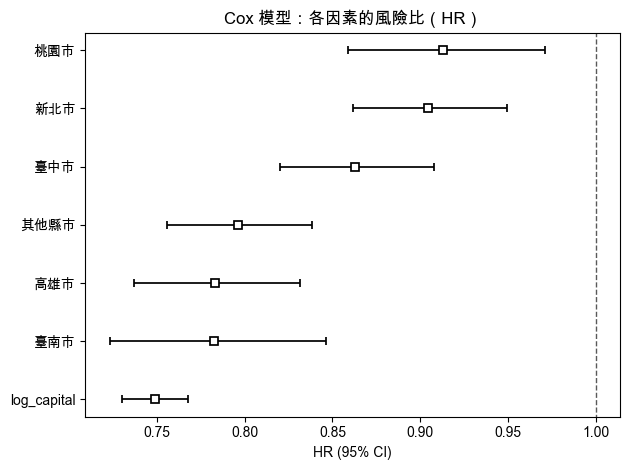

In [12]:
cph.plot(hazard_ratios=True)
plt.title("Cox 模型：各因素的風險比（HR）")
plt.tight_layout()
plt.savefig("../reports/figures/cox_forest.png", dpi=150)
plt.show()

In [13]:
from lifelines.statistics import proportional_hazard_test

ph_test = proportional_hazard_test(cph, model_df, time_transform="rank")
print(ph_test.summary[["test_statistic", "p"]].round(4))

             test_statistic       p
log_capital         28.4941  0.0000
其他縣市                 8.2029  0.0042
新北市                 10.3020  0.0013
桃園市                  7.2274  0.0072
臺中市                  2.8907  0.0891
臺南市                  8.2504  0.0041
高雄市                  4.6171  0.0317


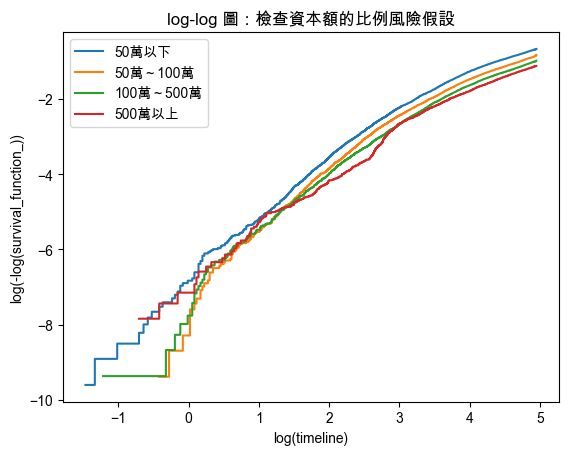

In [14]:
from lifelines import KaplanMeierFitter

df["capital_group"] = pd.cut(
    df["capital"],
    bins=[0, 500_000, 1_000_000, 5_000_000, float("inf")],
    labels=["50萬以下", "50萬～100萬", "100萬～500萬", "500萬以上"],
)

fig, ax = plt.subplots()
for group in df["capital_group"].cat.categories:
    sub = df[df["capital_group"] == group]
    kmf = KaplanMeierFitter()
    kmf.fit(sub["duration_months"], sub["event"], label=group)
    kmf.plot_loglogs(ax=ax)

ax.set_title("log-log 圖：檢查資本額的比例風險假設")
plt.savefig("../reports/figures/ph_loglog_capital.png", dpi=150)
plt.show()

In [15]:
# ===== 1. 第一年的資料 =====
year1 = model_df.copy()
over_12 = year1["duration_months"] > 12
year1.loc[over_12, "duration_months"] = 12
year1.loc[over_12, "event"] = 0

# ===== 2. 第一年後的資料 =====
after = model_df[model_df["duration_months"] > 12].copy()
after["duration_months"] = after["duration_months"] - 12

print("第一年：", len(year1), "家，其中解散", year1["event"].sum(), "家")
print("第一年後：", len(after), "家，其中解散", after["event"].sum(), "家")

# ===== 3. 分別跑 Cox =====
cph_year1 = CoxPHFitter()
cph_year1.fit(year1, duration_col="duration_months", event_col="event")

cph_after = CoxPHFitter()
cph_after.fit(after, duration_col="duration_months", event_col="event")

# ===== 4. 比較資本額的 HR =====
cols = ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]
compare = pd.DataFrame({
    "整體（原模型）": cph.summary.loc["log_capital", cols],
    "第一年": cph_year1.summary.loc["log_capital", cols],
    "第一年後": cph_after.summary.loc["log_capital", cols],
}).T
print()
print(compare.round(3))

# ===== 5. 第一年後的模型，假設檢定有沒有改善？ =====
ph_after = proportional_hazard_test(cph_after, after, time_transform="rank")
print()
print(ph_after.summary[["test_statistic", "p"]].round(4))

第一年： 43632 家，其中解散 1912 家
第一年後： 41720 家，其中解散 12947 家

         exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%    p
整體（原模型）      0.749                0.730                0.768  0.0
第一年          0.634                0.592                0.679  0.0
第一年後         0.768                0.747                0.789  0.0

             test_statistic       p
log_capital          9.1360  0.0025
其他縣市                10.5615  0.0012
新北市                 14.6766  0.0001
桃園市                  8.2493  0.0041
臺中市                  6.0666  0.0138
臺南市                  6.5119  0.0107
高雄市                  7.6737  0.0056
